In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
import cv2  # CHỈ dùng để đọc ảnh và trong ô ĐỐI CHIẾU

In [2]:
# Sử dụng hàm convolve2d của Gấm
def convolve2d(image, kernel, padding="constant"):
    image = np.asarray(image, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)

    if image.ndim != 2 or kernel.ndim != 2:
        raise ValueError("Image và kernel phải là mảng 2 chiều")

    kh, kw = kernel.shape

    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError("Kernel phải có kích thước lẻ")

    if padding not in ("constant", "reflect", "edge"):
        raise ValueError("Padding không hợp lệ")

    ph, pw = kh // 2, kw // 2

    padded = np.pad(
        image,
        ((ph, ph), (pw, pw)),
        mode=padding
    )

    flipped = np.flip(kernel, axis=(0, 1))

    h, w = image.shape
    output = np.zeros((h, w), dtype=np.float64)

    for i in range(h):
        for j in range(w):
            region = padded[i:i+kh, j:j+kw]
            output[i, j] = np.sum(region * flipped)

    return output

## Tấn Lên – Demo 3b: Phát hiện biên Sobel và Làm sắc nét ảnh

**Mục tiêu:**
- Áp dụng các kernel Sobel X và Sobel Y để tính toán gradient của ảnh.
- Tính toán độ lớn và hướng của gradient.
- Áp dụng toán tử Laplacian để làm sắc nét ảnh.
- Trực quan hóa và phân tích kết quả xử lý.

Các thí nghiệm sử dụng hàm `convolve2d` của nhóm để thực hiện phép chập với các kernel khác nhau.

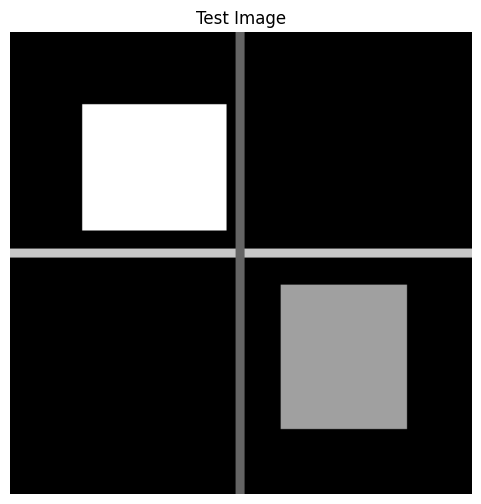

In [3]:
#  Tạo ảnh thử nghiệm 
height, width = 256, 256
img_demo = np.zeros((height, width), dtype=np.uint8)

# Add bright and gray rectangles
img_demo[40:110, 40:120] = 255
img_demo[140:220, 150:220] = 160

# Add horizontal and vertical structures
img_demo[120:125, :] = 200
img_demo[:, 125:130] = 100

# Display the test image
plt.figure(figsize=(6, 6))
plt.imshow(img_demo, cmap="gray", vmin=0, vmax=255)
plt.title("Test Image")
plt.axis("off")
plt.show()

In [4]:
 
# Sobel edge detection

img_float = img_demo.astype(np.float64)

sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float64)

sobel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=np.float64)

# convolve2d thực hiện tích chập thật nên cần lật kernel
sobel_x_conv = np.flip(sobel_x, axis=(0, 1))
sobel_y_conv = np.flip(sobel_y, axis=(0, 1))

gx = convolve2d(
    img_float, sobel_x_conv, padding="reflect"
)

gy = convolve2d(
    img_float, sobel_y_conv, padding="reflect"
)

edge_magnitude = np.sqrt(gx**2 + gy**2)

edge_direction = np.degrees(
    np.arctan2(gy, gx)
)

print("Sobel completed!")
print("gx:", gx.shape)
print("gy:", gy.shape)
 

Sobel completed!
gx: (256, 256)
gy: (256, 256)


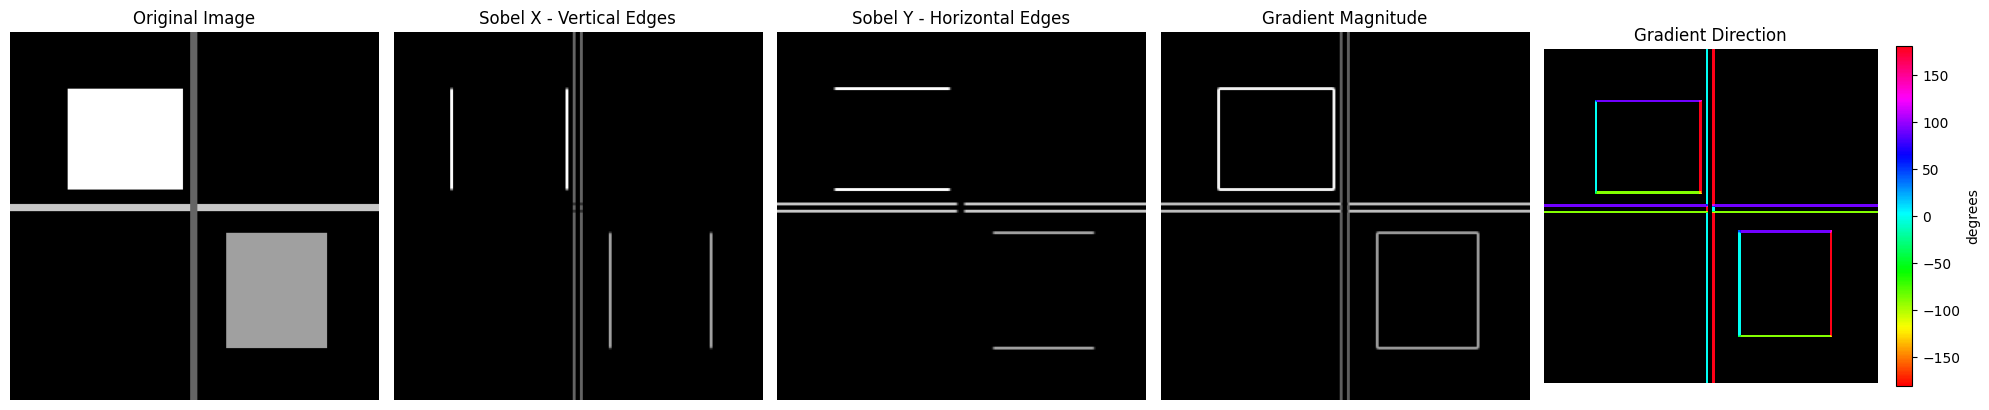

In [5]:
 
# Visualize Sobel edge detection

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

axes[0].imshow(img_demo, cmap="gray")
axes[0].set_title("Original Image")

axes[1].imshow(np.abs(gx), cmap="gray")
axes[1].set_title("Sobel X - Vertical Edges")

axes[2].imshow(np.abs(gy), cmap="gray")
axes[2].set_title("Sobel Y - Horizontal Edges")

axes[3].imshow(edge_magnitude, cmap="gray")
axes[3].set_title("Gradient Magnitude")

# Chỉ tô màu hướng ở pixel có cạnh; vùng phẳng (gx = gy = 0) để đen
direction_display = np.where(edge_magnitude > 0, edge_direction, np.nan)
direction_cmap = plt.get_cmap("hsv").copy()
direction_cmap.set_bad("black")
im = axes[4].imshow(direction_display, cmap=direction_cmap, vmin=-180, vmax=180,
                    interpolation="nearest")
axes[4].set_title("Gradient Direction")
fig.colorbar(im, ax=axes[4], fraction=0.046, label="degrees")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

**Nhận xét Sobel:**
- Sobel X phản ứng với thay đổi cường độ theo chiều ngang nên chỉ hiện các **cạnh dọc** (mép trái/phải hình chữ nhật, vạch dọc); Sobel Y ngược lại chỉ hiện **cạnh ngang**.
- Độ lớn gradient $\sqrt{g_x^2 + g_y^2}$ gộp cả hai hướng nên ra đủ viền. Hình chữ nhật trắng (255) cho viền sáng hơn hình xám (160) vì bước nhảy cường độ lớn hơn.
- Hướng gradient chỉ từ tối sang sáng: mép trái hình sáng ≈ 0°, mép phải ≈ ±180°, mép trên ≈ −90°, mép dưới ≈ 90°. Vùng phẳng không có hướng nên để đen.

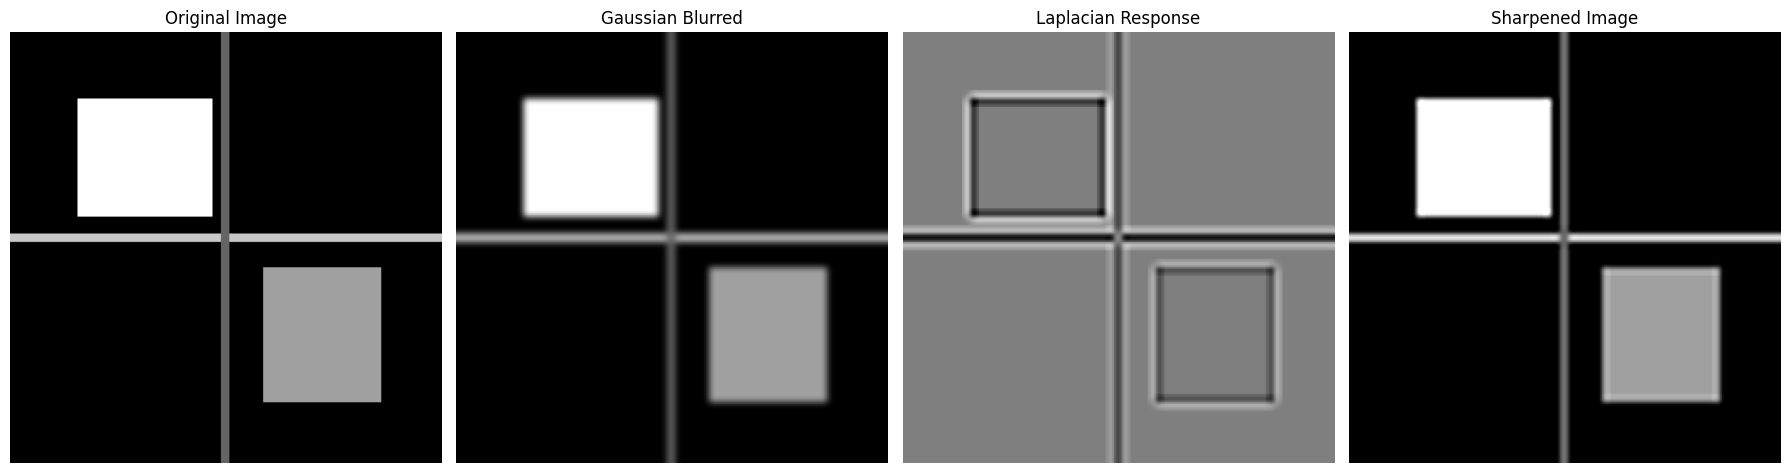

In [6]:
# Convert original image to float64
img_float = img_demo.astype(np.float64)

# Kernel Gauss tự viết, làm mờ bằng convolve2d của nhóm
def gaussian_kernel(size, sigma):
    r = size // 2
    y, x = np.mgrid[-r:r + 1, -r:r + 1]
    kernel = np.exp(-(x**2 + y**2) / (2 * sigma**2))
    return kernel / kernel.sum()

# Blur the image first to make the sharpening effect more visible
img_blurred = convolve2d(
    img_float,
    gaussian_kernel(9, 2.0),
    padding="reflect"
)

# 4-neighbor Laplacian kernel
laplacian_kernel = np.array([
    [ 0,  1,  0],
    [ 1, -4,  1],
    [ 0,  1,  0]
], dtype=np.float64)

# Apply Laplacian to the blurred image
laplacian = convolve2d(
    img_blurred,
    laplacian_kernel,
    padding="reflect"
)

# Sharpen the blurred image
alpha = 3.0
sharpened_float = img_blurred - alpha * laplacian

# Clip to valid image range
sharpened = np.clip(
    np.round(sharpened_float), 0, 255
).astype(np.uint8)

# Convert for display
img_blurred_display = np.clip(
    np.round(img_blurred), 0, 255
).astype(np.uint8)

# Kéo giãn quanh mức xám 127.5 theo giá trị tuyệt đối lớn nhất để thấy rõ viền
laplacian_display = np.clip(
    127.5 + 127.5 * laplacian / np.abs(laplacian).max(), 0, 255
).astype(np.uint8)

# Compare original, blurred, Laplacian and sharpened images
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(img_demo, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Image")

axes[1].imshow(
    img_blurred_display, cmap="gray", vmin=0, vmax=255
)
axes[1].set_title("Gaussian Blurred")

axes[2].imshow(
    laplacian_display, cmap="gray", vmin=0, vmax=255
)
axes[2].set_title("Laplacian Response")

axes[3].imshow(sharpened, cmap="gray", vmin=0, vmax=255)
axes[3].set_title("Sharpened Image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

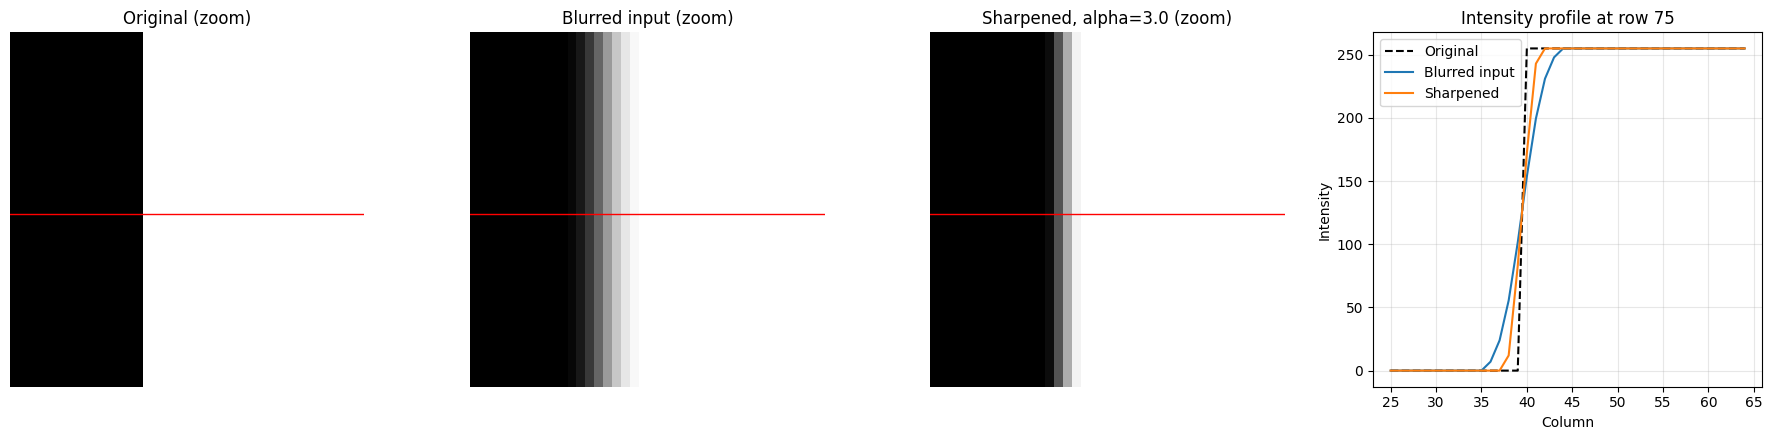

Edge width - blurred:   4 px
Edge width - sharpened: 2 px


In [7]:
# Phóng to vùng cạnh để so sánh gốc / mờ / sắc nét
r0, r1, c0, c1 = 55, 95, 25, 65   # vùng quanh cạnh trái của hình chữ nhật sáng
row = 75                          # hàng dùng để vẽ mặt cắt cường độ

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

for ax, im, title in zip(
    axes[:3],
    [img_demo, img_blurred_display, sharpened],
    ["Original (zoom)", "Blurred input (zoom)", f"Sharpened, alpha={alpha} (zoom)"]
):
    ax.imshow(im[r0:r1, c0:c1], cmap="gray", vmin=0, vmax=255,
              interpolation="nearest")
    ax.axhline(row - r0, color="red", linewidth=1)
    ax.set_title(title)
    ax.axis("off")

cols = np.arange(c0, c1)
axes[3].plot(cols, img_demo[row, c0:c1], "k--", label="Original")
axes[3].plot(cols, img_blurred[row, c0:c1], label="Blurred input")
axes[3].plot(cols, sharpened[row, c0:c1], label="Sharpened")
axes[3].set_xlabel("Column")
axes[3].set_ylabel("Intensity")
axes[3].set_title(f"Intensity profile at row {row}")
axes[3].legend()
axes[3].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Độ rộng vùng chuyển (pixel có cường độ 10%–90%) càng nhỏ thì cạnh càng sắc
def edge_width(profile):
    return int(np.sum((profile > 25.5) & (profile < 229.5)))

print("Edge width - blurred:  ", edge_width(img_blurred[row, c0:c1]), "px")
print("Edge width - sharpened:", edge_width(sharpened[row, c0:c1]), "px")

**Nhận xét làm sắc nét:**
- Laplacian bằng 0 ở vùng phẳng và đổi dấu hai bên cạnh, nên $I - \alpha \nabla^2 I$ kéo phía tối tối hơn, phía sáng sáng hơn → cạnh dốc lại (độ rộng vùng chuyển giảm từ 4 px còn 2 px).
- Làm sắc nét không khôi phục được chi tiết đã mất do làm mờ, chỉ làm tăng tương phản tại cạnh. Với cạnh 0 → 255, phần vọt lố bị cắt ở 0 và 255 nên không thấy trên mặt cắt.
- $\alpha$ càng lớn cạnh càng sắc nhưng càng dễ sinh viền sáng/tối giả (vọt lố) và khuếch đại nhiễu.

In [8]:
# Kiểm tra kích thước, kiểu dữ liệu và kết quả

# 1. Kiểm tra các biến đầu vào đã tồn tại chưa
required_vars = [
    "img_demo",
    "gx",
    "gy",
    "edge_magnitude",
    "edge_direction",
    "laplacian",
    "sharpened"
]

missing_vars = [
    name for name in required_vars
    if name not in globals()
]

if missing_vars:
    print("ERROR: Các biến chưa được tạo:", missing_vars)
    print("Hãy chạy lại các cell tạo ảnh, Sobel và Laplacian ở phía trên.")
else:
    # 2. In kích thước và kiểu dữ liệu
    print("Original image:", img_demo.shape, img_demo.dtype)
    print("Sobel X:", gx.shape, gx.dtype)
    print("Sobel Y:", gy.shape, gy.dtype)
    print("Gradient magnitude:", edge_magnitude.shape,
          edge_magnitude.dtype)
    print("Gradient direction:", edge_direction.shape,
          edge_direction.dtype)
    print("Laplacian:", laplacian.shape, laplacian.dtype)
    print("Sharpened image:", sharpened.shape, sharpened.dtype)

    # 3. Thống kê gradient
    print("\nMaximum gradient magnitude:",
          float(np.max(edge_magnitude)))

    print("Number of pixels with nonzero gradient:",
          int(np.count_nonzero(edge_magnitude)))

    # 4. Kiểm tra các đầu ra có cùng kích thước không
    all_shapes_match = (
        img_demo.shape == gx.shape
        == gy.shape
        == edge_magnitude.shape
        == edge_direction.shape
        == laplacian.shape
        == sharpened.shape
    )

    print("All output shapes match:", all_shapes_match)

    # 5. Kiểm tra giá trị không hợp lệ
    arrays_to_check = {
        "gx": gx,
        "gy": gy,
        "edge_magnitude": edge_magnitude,
        "edge_direction": edge_direction,
        "laplacian": laplacian,
        "sharpened": sharpened
    }

    for name, array in arrays_to_check.items():
        print(
            f"{name} contains NaN/Inf:",
            bool(np.any(~np.isfinite(array)))
        )


Original image: (256, 256) uint8
Sobel X: (256, 256) float64
Sobel Y: (256, 256) float64
Gradient magnitude: (256, 256) float64
Gradient direction: (256, 256) float64
Laplacian: (256, 256) float64
Sharpened image: (256, 256) uint8

Maximum gradient magnitude: 1081.8733752154178
Number of pixels with nonzero gradient: 3220
All output shapes match: True
gx contains NaN/Inf: False
gy contains NaN/Inf: False
edge_magnitude contains NaN/Inf: False
edge_direction contains NaN/Inf: False
laplacian contains NaN/Inf: False
sharpened contains NaN/Inf: False


# KT3 – Bỏ phiếu Hough: `hough_accumulate`, `find_peaks`  _(Tấn Lên)_

Theo Computer_Vision_40.pdf, mục 4.1, 4.4–4.6.

**Quy ước** (giống ảnh thử của Gấm và `hough_multiscale` của Hiệp):
- Đường thẳng: $\rho = x\cos\theta + y\sin\theta$, gốc tọa độ ở góc trên trái, $x$ = cột, $y$ = hàng.
- Mặc định $\theta \in [0, \pi)$ (180 giá trị), $\rho \in [-D, D]$ với $D$ = đường chéo ảnh, bước 1 px.
- Hai cặp $(\rho, \theta)$ và $(-\rho, \theta + \pi)$ là cùng một đường → cột $\theta$ cuối nối với cột $\theta = 0$ khi lật dấu $\rho$ (mục 4.3, bẫy quấn vòng).

**Giao diện** (theo đặc tả mục 4.6; các tham số có giá trị mặc định là nhóm thêm cho tiện gọi):
- `hough_accumulate(edges, theta_range=(0, π), rho_range=None, n_theta=180, n_rho=None, grad_dir=None, delta_deg=None)` → `(A, thetas, rhos)`, với `A[i, j]` là số phiếu của $(\rho_i, \theta_j)$.
  - `theta_range` tính bằng radian, lấy `n_theta` giá trị cách đều, không lấy đầu mút cuối.
  - `rho_range` lấy `n_rho` giá trị cách đều, có cả hai đầu mút.
  - Khi truyền `grad_dir` (radian), mỗi điểm cạnh chỉ bỏ phiếu cho các $\theta$ lệch không quá `delta_deg` **độ** so với hướng gradient, so sánh theo modulo 180° (mục 4.4). Nếu `delta_deg=None` thì dùng 15°, trong khoảng 5°–15° tài liệu gợi ý.
- `find_peaks(A, n_peaks, nms_radius=3, smooth_sigma=1.0, thetas=None, rhos=None)` → danh sách `(rho, theta, votes)` sắp giảm dần theo `votes`.
  - Đặc tả chỉ có `A` nên nhóm thêm `thetas`, `rhos` (tùy chọn, đặt sau cùng) để đổi chỉ số ô ra giá trị $(\rho, \theta)$. Nếu không truyền thì trả về chỉ số ô.
  - Chỉ quấn vòng $\theta$ khi có `thetas`, `rhos`, lưới phủ đúng $[0, \pi)$ và trục $\rho$ đối xứng.

**Quy ước của nhóm cho `find_peaks`** (tài liệu mục 4.5 chỉ ghi "tích chập với nhân Gauss nhỏ, σ ≈ 1 ô", không ghi làm mờ theo trục nào, cũng không ghi `votes` lấy trước hay sau làm mờ):
- `smooth_sigma` là độ lệch chuẩn Gauss **theo trục $\rho$**, tính bằng ô tích lũy; `smooth_sigma=0` là không làm mờ. Đây là **lựa chọn của nhóm**: làm mờ theo $\rho$ đủ để gom phiếu bị chẻ sang ô $\rho$ kề nhau, còn làm mờ thêm theo $\theta$ kéo lệch đỉnh của đoạn ngắn. Phần so sánh hai cách nằm ở ô kiểm thử bên dưới.
- `votes` là **điểm tích lũy sau làm mờ**: giá trị tại đỉnh trên bảng đã làm mờ (số thực). Khi `smooth_sigma=0`, đó là số phiếu gốc. Danh sách đỉnh sắp giảm dần theo chính giá trị này.
- Triệt phi cực đại: lặp lấy ô lớn nhất → xóa hình vuông bán kính `nms_radius` ô quanh nó → lấy ô lớn tiếp theo. Kết quả là chỉ giữ đỉnh trội trong bán kính cho trước (mục 4.5).

## KT3 – Hàm tự viết

In [9]:
def hough_accumulate(edges, theta_range=(0, np.pi), rho_range=None,
                     n_theta=180, n_rho=None, grad_dir=None, delta_deg=None):
    """Bỏ phiếu vào mảng tích lũy. Nếu grad_dir khác None, chỉ bỏ phiếu
    trong dải +/- delta_deg (độ) quanh hướng gradient.
    Trả về (A, thetas, rhos), A có kích thước (n_rho, n_theta)."""
    edges = np.asarray(edges)
    if edges.ndim != 2:
        raise ValueError("edges phải là ảnh hai chiều")

    h, w = edges.shape
    ys, xs = np.nonzero(edges)

    # Trục theta: n_theta giá trị cách đều trong [theta_min, theta_max)
    theta_min, theta_max = theta_range
    if int(n_theta) != n_theta or n_theta < 1 or not theta_min < theta_max:
        raise ValueError("theta_range, n_theta không hợp lệ")
    n_theta = int(n_theta)
    thetas = theta_min + np.arange(n_theta) * (theta_max - theta_min) / n_theta

    # Trục rho: mặc định [-D, D] với D = đường chéo ảnh, bước 1 px
    if rho_range is None:
        D = np.ceil(np.hypot(h - 1, w - 1))
        rho_range = (-D, D)
    rho_min, rho_max = rho_range
    if n_rho is None:
        n_rho = int(round(rho_max - rho_min)) + 1
    if int(n_rho) != n_rho or n_rho < 2 or not rho_min < rho_max:
        raise ValueError("rho_range, n_rho không hợp lệ")
    n_rho = int(n_rho)
    rhos = np.linspace(rho_min, rho_max, n_rho)
    rho_step = (rho_max - rho_min) / (n_rho - 1)

    if grad_dir is not None:
        grad_dir = np.asarray(grad_dir, dtype=np.float64)
        if grad_dir.shape != edges.shape:
            raise ValueError("grad_dir phải cùng kích thước với edges")
        if delta_deg is None:
            delta_deg = 15.0   # tài liệu gợi ý 5°–15°
        if not 0 < delta_deg <= 90:
            raise ValueError("delta_deg phải thuộc (0, 90] độ")
        # Hướng pháp tuyến chỉ có nghĩa theo modulo 180°
        g = grad_dir[ys, xs] % np.pi
        delta = np.deg2rad(delta_deg)

    A = np.zeros((n_rho, n_theta), dtype=np.int64)

    # Với mỗi theta, mọi điểm cạnh cùng bỏ phiếu cho ô rho của mình
    for j, theta in enumerate(thetas):
        rho = xs * np.cos(theta) + ys * np.sin(theta)
        idx = np.rint((rho - rho_min) / rho_step).astype(int)
        hop_le = (idx >= 0) & (idx < n_rho)

        if grad_dir is not None:
            lech = np.abs((g - theta + np.pi / 2) % np.pi - np.pi / 2)
            hop_le &= lech <= delta

        A[:, j] = np.bincount(idx[hop_le], minlength=n_rho)

    return A, thetas, rhos

In [10]:
def smooth_accumulator(A, smooth_sigma=1.0):
    """Làm mờ bảng phiếu theo trục rho bằng kernel Gauss 1 chiều."""
    A = np.asarray(A, dtype=np.float64)
    if smooth_sigma <= 0:
        return A.copy()
    r = int(np.ceil(3 * smooth_sigma))
    x = np.arange(-r, r + 1)
    kernel = np.exp(-x**2 / (2 * smooth_sigma**2))
    kernel = (kernel / kernel.sum())[:, None]   # cột (2r+1) x 1: chỉ làm mờ theo rho
    return convolve2d(A, kernel, padding="constant")


def find_peaks(A, n_peaks, nms_radius=3, smooth_sigma=1.0,
               thetas=None, rhos=None, threshold=0):
    """Làm mượt A bằng convolve2d của nhóm (Gauss theo trục rho, smooth_sigma
    tính bằng ô), triệt phi cực đại, trả về danh sách (rho, theta, votes) sắp
    giảm dần. votes là điểm tích lũy trên bảng đã làm mờ; smooth_sigma=0 thì
    votes là số phiếu gốc. Không truyền thetas, rhos thì rho, theta là chỉ số ô."""
    A = np.asarray(A)
    if A.ndim != 2:
        raise ValueError("A phải là mảng hai chiều")
    if int(n_peaks) != n_peaks or n_peaks < 1:
        raise ValueError("n_peaks phải là số nguyên dương")
    if int(nms_radius) != nms_radius or nms_radius < 0:
        raise ValueError("nms_radius phải là số nguyên không âm")
    nms_radius = int(nms_radius)
    if (thetas is None) != (rhos is None):
        raise ValueError("Phải truyền cả thetas và rhos, hoặc không truyền cả hai")
    if thetas is not None:
        thetas, rhos = np.asarray(thetas), np.asarray(rhos)
        if A.shape != (len(rhos), len(thetas)):
            raise ValueError("A phải có kích thước (len(rhos), len(thetas))")

    # Không làm mờ theo theta: kéo đỉnh của đoạn ngắn lệch góc (xem kiểm thử bên dưới)
    S = smooth_accumulator(A, smooth_sigma)
    n_rho, n_theta = S.shape

    # Chỉ quấn vòng theta khi lưới phủ đúng [0, pi) và trục rho đối xứng quanh 0
    wrap = (thetas is not None
            and np.isclose(thetas[0], 0) and np.isclose(thetas[-1] + np.pi / n_theta, np.pi)
            and np.allclose(rhos, -rhos[::-1]))

    remaining = S.copy()
    peaks = []

    for _ in range(int(n_peaks)):
        i, j = np.unravel_index(np.argmax(remaining), remaining.shape)
        if remaining[i, j] <= threshold:
            break
        if thetas is None:
            peaks.append((float(i), float(j), float(S[i, j])))
        else:
            peaks.append((float(rhos[i]), float(thetas[j]), float(S[i, j])))

        # Xóa hình vuông bán kính nms_radius quanh đỉnh vừa lấy
        for dj in range(-nms_radius, nms_radius + 1):
            jj, ii = j + dj, i
            if jj < 0 or jj >= n_theta:
                if not wrap:
                    continue
                jj %= n_theta
                ii = n_rho - 1 - i      # cột bên kia biên: rho đổi dấu
            r0 = max(0, ii - nms_radius)
            r1 = min(n_rho, ii + nms_radius + 1)
            remaining[r0:r1, jj] = 0

    # Sắp giảm dần theo điểm tích lũy sau làm mờ
    peaks.sort(key=lambda peak: peak[2], reverse=True)
    return peaks

## KT3 – Ảnh thử

Ảnh `hough_test.png` của Gấm, đáp án: đoạn dài $\rho_0 = 110,\ \theta_0 = 3^\circ$ (300 px) và đoạn ngắn $\rho = 270,\ \theta = 3^\circ$ (20 px).

**Lấy điểm cạnh bằng Sobel tự viết** (không lấy thẳng các pixel của đường): đường chỉ dày 1 px nên ngay trên đường hai bên đều tối, Sobel cho $g_x \approx g_y \approx 0$ → hướng gradient vô nghĩa. Điểm cạnh thật nằm ở hai mép đường, ở đó hướng gradient đúng bằng pháp tuyến ($\approx 3^\circ$ hoặc $183^\circ$, cùng là $3^\circ$ theo modulo 180°).

Kích thước ảnh: (400, 400)
Số điểm cạnh: 724


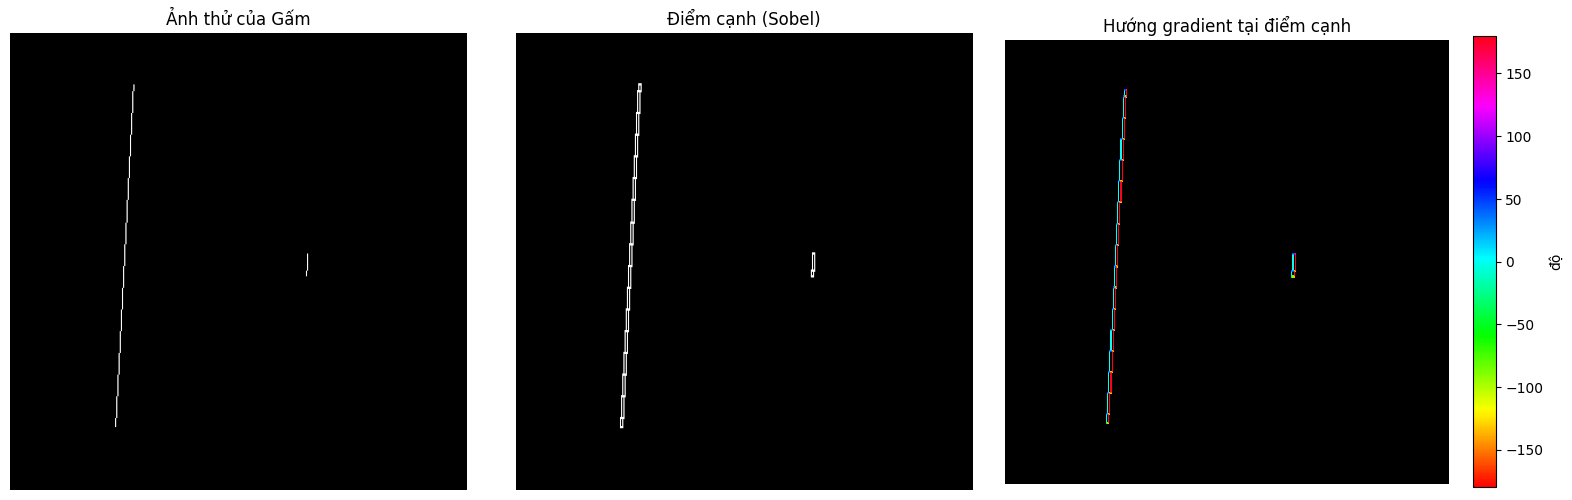

In [11]:
from pathlib import Path

IMAGE_DIR = Path.cwd().parent / "images" if Path.cwd().name == "lam_viec" else Path.cwd() / "images"

test_image = cv2.imread(str(IMAGE_DIR / "hough_test.png"), cv2.IMREAD_GRAYSCALE)
if test_image is None:
    raise FileNotFoundError("Không đọc được images/hough_test.png")

# Đáp án của Gấm: (rho, theta độ, độ dài)
ground_truth = [(110, 3, 300), (270, 3, 20)]
rho0, theta0_deg = 110, 3

sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]], dtype=np.float64)
sobel_y = sobel_x.T


def sobel_edges(image, ratio=0.3):
    image = image.astype(np.float64)
    # Lật kernel vì convolve2d là tích chập thật
    gx = convolve2d(image, np.flip(sobel_x), padding="reflect")
    gy = convolve2d(image, np.flip(sobel_y), padding="reflect")
    magnitude = np.hypot(gx, gy)
    edges = magnitude > ratio * magnitude.max()
    return edges, np.arctan2(gy, gx)


edge_map, gradient_direction = sobel_edges(test_image)
print("Kích thước ảnh:", test_image.shape)
print("Số điểm cạnh:", int(edge_map.sum()))

direction_display = np.where(edge_map, np.rad2deg(gradient_direction), np.nan)
direction_cmap = plt.get_cmap("hsv").copy()
direction_cmap.set_bad("black")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(test_image, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Ảnh thử của Gấm")
axes[1].imshow(edge_map, cmap="gray")
axes[1].set_title("Điểm cạnh (Sobel)")
im = axes[2].imshow(direction_display, cmap=direction_cmap, vmin=-180, vmax=180,
                    interpolation="nearest")
axes[2].set_title("Hướng gradient tại điểm cạnh")
fig.colorbar(im, ax=axes[2], fraction=0.046, label="độ")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## KT3 – Thí nghiệm: bỏ phiếu thường và bỏ phiếu theo gradient

Bỏ phiếu thường (0.69 s):
  rho (px) | theta (độ) | điểm tích lũy (sau làm mờ)
     110.0 |        3.0 |  162.6
     106.0 |        2.0 |  113.4
     114.0 |        4.0 |  113.0
     118.0 |        5.0 |   63.5
     102.0 |        1.0 |   63.3

Bỏ phiếu theo gradient (0.68 s):
  rho (px) | theta (độ) | điểm tích lũy (sau làm mờ)
     110.0 |        3.0 |  128.8
     114.0 |        4.0 |  101.6
     106.0 |        2.0 |   91.2
     118.0 |        5.0 |   57.5
     102.0 |        1.0 |   51.3



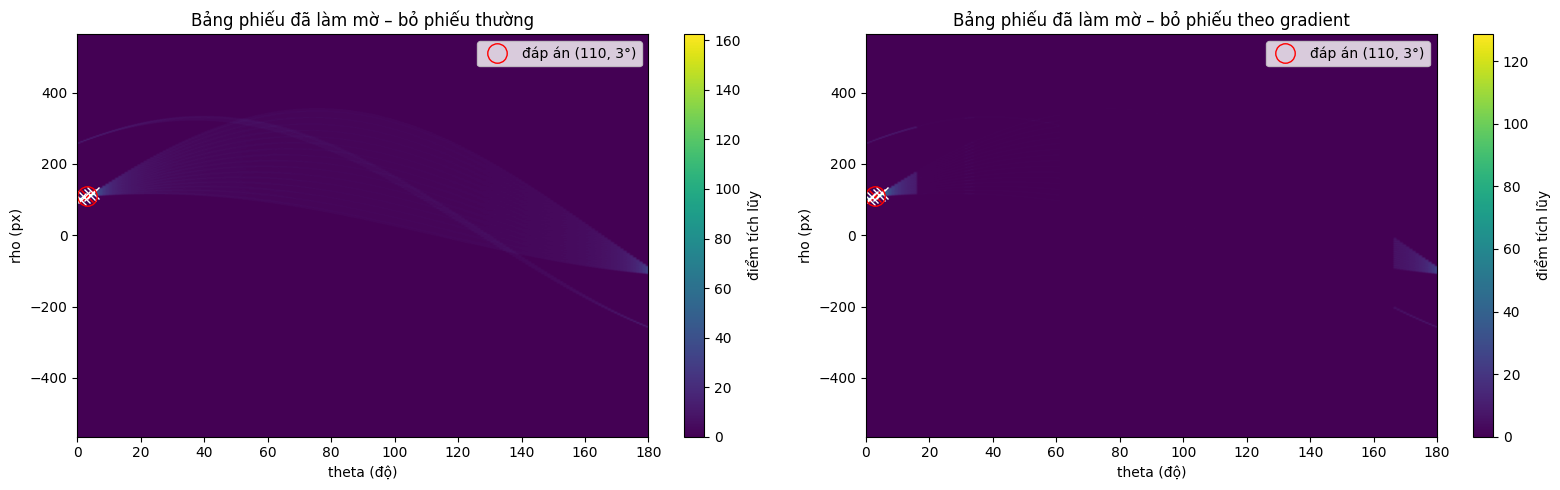

Tổng số phiếu – thường: 130320 | theo gradient: 21716 (giảm 83.3%)


In [12]:
def print_peaks(title, peaks):
    print(title)
    print("  rho (px) | theta (độ) | điểm tích lũy (sau làm mờ)")
    for rho, theta, votes in peaks:
        print(f"  {rho:8.1f} | {np.rad2deg(theta):10.1f} | {votes:6.1f}")


def show_accumulator(ax, A, rhos, thetas, peaks, title):
    im = ax.imshow(A, aspect="auto", origin="lower", cmap="viridis",
                   extent=[0, 180, rhos[0], rhos[-1]])
    for k, (rho, theta, _) in enumerate(peaks):
        ax.plot(np.rad2deg(theta), rho, "rx" if k == 0 else "wx", markersize=8)
    ax.plot(theta0_deg, rho0, "o", mfc="none", mec="red", markersize=14, label="đáp án (110, 3°)")
    ax.set_xlabel("theta (độ)")
    ax.set_ylabel("rho (px)")
    ax.set_title(title)
    ax.legend(loc="upper right")
    return im


results = {}
for name, grad in [("thường", None), ("theo gradient", gradient_direction)]:
    t0 = time.time()
    A, thetas, rhos = hough_accumulate(edge_map, grad_dir=grad)
    peaks = find_peaks(A, 5, thetas=thetas, rhos=rhos)
    results[name] = (A, smooth_accumulator(A), peaks)
    print_peaks(f"Bỏ phiếu {name} ({time.time() - t0:.2f} s):", peaks)
    print()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (name, (A, A_smooth, peaks)) in zip(axes, results.items()):
    im = show_accumulator(ax, A_smooth, rhos, thetas, peaks, f"Bảng phiếu đã làm mờ – bỏ phiếu {name}")
    fig.colorbar(im, ax=ax, label="điểm tích lũy")
plt.tight_layout()
plt.show()

A_plain, A_grad = results["thường"][0], results["theo gradient"][0]
print("Tổng số phiếu – thường:", int(A_plain.sum()), "| theo gradient:", int(A_grad.sum()),
      f"(giảm {100 * (1 - A_grad.sum() / A_plain.sum()):.1f}%)")

## KT3 – Kiểm tra đỉnh đúng $(\rho_0, \theta_0)$

In [13]:
def angle_distance_deg(a, b):
    """Sai số góc giữa hai pháp tuyến, theo modulo 180°."""
    d = abs(a - b) % 180
    return min(d, 180 - d)


def check_peak(peak, rho0, theta0_deg, rho_tol=2, theta_tol_deg=1):
    rho, theta, _ = peak
    theta_deg = np.rad2deg(theta)
    # Nếu lệch quá 90° thì đổi sang cặp (-rho, theta ± 180°)
    if abs(theta_deg - theta0_deg) > 90:
        rho = -rho
    e_theta = angle_distance_deg(theta_deg, theta0_deg)
    e_rho = abs(rho - rho0)
    return e_rho <= rho_tol and e_theta <= theta_tol_deg, e_rho, e_theta


print(f"Đáp án: rho0 = {rho0}, theta0 = {theta0_deg}°")
print("Dung sai nhóm tự đặt (tài liệu không quy định): 2 px, 1°\n")
for name, (_, _, peaks) in results.items():
    ok, e_rho, e_theta = check_peak(peaks[0], rho0, theta0_deg)
    print(f"Bỏ phiếu {name:13s}: đỉnh mạnh nhất = ({peaks[0][0]:.0f}, {np.rad2deg(peaks[0][1]):.0f}°)"
          f" | sai số rho = {e_rho:.0f} px, góc = {e_theta:.0f}° -> {'ĐẠT' if ok else 'KHÔNG ĐẠT'}")

# Đoạn ngắn 20 px: xem điểm tại đúng ô đáp án so với đỉnh thứ hai
A_smooth = results["thường"][1]
i270 = np.argmin(np.abs(rhos - 270))
j3 = np.argmin(np.abs(np.rad2deg(thetas) - 3))
print(f"\nĐoạn ngắn (270, 3°): điểm tích lũy tại ô đáp án = {A_smooth[i270, j3]:.1f}, "
      f"đỉnh thứ hai = {results['thường'][2][1][2]:.1f}")

Đáp án: rho0 = 110, theta0 = 3°
Dung sai nhóm tự đặt (tài liệu không quy định): 2 px, 1°

Bỏ phiếu thường       : đỉnh mạnh nhất = (110, 3°) | sai số rho = 0 px, góc = 0° -> ĐẠT
Bỏ phiếu theo gradient: đỉnh mạnh nhất = (110, 3°) | sai số rho = 0 px, góc = 0° -> ĐẠT

Đoạn ngắn (270, 3°): điểm tích lũy tại ô đáp án = 13.2, đỉnh thứ hai = 113.4


In [14]:
for filename, r_true, t_true in [("hough_angle_0_5.png", 200, 0.5),
                                 ("hough_angle_179_5.png", -200, 179.5)]:
    image = cv2.imread(str(IMAGE_DIR / filename), cv2.IMREAD_GRAYSCALE)
    edges, grad = sobel_edges(image)
    print(f"{filename}: đáp án ({r_true}, {t_true}°), dung sai nhóm tự đặt 3 px, 1° (tài liệu không quy định)")
    for name, g in [("thường", None), ("theo gradient", grad)]:
        A, thetas_t, rhos_t = hough_accumulate(edges, grad_dir=g)
        peaks = find_peaks(A, 1, thetas=thetas_t, rhos=rhos_t)
        ok, e_rho, e_theta = check_peak(peaks[0], r_true, t_true, rho_tol=3, theta_tol_deg=1)
        print(f"  {name:13s}: ({peaks[0][0]:.0f}, {np.rad2deg(peaks[0][1]):.0f}°)"
              f" | sai số rho = {e_rho:.1f} px, góc = {e_theta:.1f}° -> {'ĐẠT' if ok else 'KHÔNG ĐẠT'}")

hough_angle_0_5.png: đáp án (200, 0.5°), dung sai nhóm tự đặt 3 px, 1° (tài liệu không quy định)
  thường       : (198, 0°) | sai số rho = 2.0 px, góc = 0.5° -> ĐẠT
  theo gradient: (198, 0°) | sai số rho = 2.0 px, góc = 0.5° -> ĐẠT
hough_angle_179_5.png: đáp án (-200, 179.5°), dung sai nhóm tự đặt 3 px, 1° (tài liệu không quy định)
  thường       : (202, 0°) | sai số rho = 2.0 px, góc = 0.5° -> ĐẠT
  theo gradient: (202, 0°) | sai số rho = 2.0 px, góc = 0.5° -> ĐẠT


Tâm đoạn ngắn: (259.8, 202.5), độ phân giải góc ≈ 2.9°

Bỏ phiếu thường:
  smooth_sigma = 0: (269, 3°) | sai số rho = 1 px, sai số góc = 0° | cách tâm đoạn 1.0 px | 3 ô có điểm ≥ 90% đỉnh
  smooth_sigma = 1.0: (270, 3°) | sai số rho = 0 px, sai số góc = 0° | cách tâm đoạn 0.0 px | 21 ô có điểm ≥ 90% đỉnh

Bỏ phiếu theo gradient:
  smooth_sigma = 0: (269, 3°) | sai số rho = 1 px, sai số góc = 0° | cách tâm đoạn 1.0 px | 2 ô có điểm ≥ 90% đỉnh
  smooth_sigma = 1.0: (273, 4°) | sai số rho = 3 px, sai số góc = 1° | cách tâm đoạn 0.2 px | 15 ô có điểm ≥ 90% đỉnh



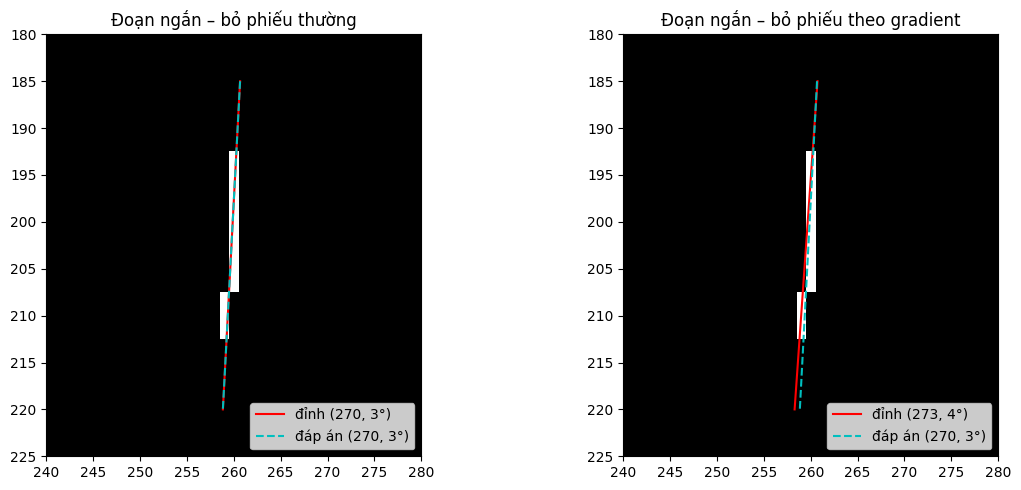

In [15]:
short_image = test_image.copy()
short_image[:, :250] = 0
short_edges, short_grad = sobel_edges(short_image)

ys_s, xs_s = np.nonzero(short_image > 127)
center_x, center_y = xs_s.mean(), ys_s.mean()
length = 20
resolution_deg = np.rad2deg(1 / length)
print(f"Tâm đoạn ngắn: ({center_x:.1f}, {center_y:.1f}), độ phân giải góc ≈ {resolution_deg:.1f}°\n")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, g) in zip(axes, [("thường", None), ("theo gradient", short_grad)]):
    A, thetas_s, rhos_s = hough_accumulate(short_edges, grad_dir=g)
    print(f"Bỏ phiếu {name}:")
    for sigma in [0, 1.0]:
        peaks = find_peaks(A, 1, smooth_sigma=sigma, thetas=thetas_s, rhos=rhos_s)
        A_used = smooth_accumulator(A, sigma)
        rho, theta, score = peaks[0]
        dist = abs(center_x * np.cos(theta) + center_y * np.sin(theta) - rho)
        e_theta = angle_distance_deg(np.rad2deg(theta), 3)
        _, e_rho, _ = check_peak(peaks[0], 270, 3)
        n_best = int(np.sum(A_used >= 0.9 * score))
        print(f"  smooth_sigma = {sigma}: ({rho:.0f}, {np.rad2deg(theta):.0f}°)"
              f" | sai số rho = {e_rho:.0f} px, sai số góc = {e_theta:.0f}°"
              f" | cách tâm đoạn {dist:.1f} px | {n_best} ô có điểm ≥ 90% đỉnh")
        if sigma > 0:
            ys_line = np.arange(185, 221)
            ax.plot((rho - ys_line * np.sin(theta)) / np.cos(theta), ys_line, "r-", label=f"đỉnh ({rho:.0f}, {np.rad2deg(theta):.0f}°)")
    ax.imshow(short_image, cmap="gray", vmin=0, vmax=255)
    ys_true = np.arange(185, 221)
    t3 = np.deg2rad(3)
    ax.plot((270 - ys_true * np.sin(t3)) / np.cos(t3), ys_true, "c--", label="đáp án (270, 3°)")
    ax.set_xlim(240, 280)
    ax.set_ylim(225, 180)
    ax.set_title(f"Đoạn ngắn – bỏ phiếu {name}")
    ax.legend(loc="lower right")
    print()
plt.tight_layout()
plt.show()

### So sánh hai cách làm mờ: chỉ theo $\rho$ (nhóm chọn) và Gauss 2 chiều
Cùng σ = 1 ô. Bản 2 chiều chỉ viết trong ô này để so sánh, không phải hàm nộp; nó nối cột θ quấn vòng (lật ρ) trước khi tích chập. Báo đỉnh mạnh nhất cùng sai số $\rho$ và sai số góc so với đáp án.

In [16]:
def smooth_2d(A, sigma=1.0):
    r = int(np.ceil(3 * sigma))
    x = np.arange(-r, r + 1)
    k = np.exp(-x**2 / (2 * sigma**2))
    k /= k.sum()
    extended = np.hstack([A[::-1, -r:], A, A[::-1, :r]])
    return convolve2d(extended, np.outer(k, k), padding="constant")[:, r:-r]


print(f"{'ảnh':10s} {'bỏ phiếu':14s} | {'chỉ theo rho':28s} | {'Gauss 2 chiều':28s}")
for label, edges_c, grad_c, (r_true, t_true) in [
        ("đoạn dài", edge_map, gradient_direction, (rho0, theta0_deg)),
        ("đoạn ngắn", short_edges, short_grad, (270, 3))]:
    for name, g in [("thường", None), ("theo gradient", grad_c)]:
        A, th, rh = hough_accumulate(edges_c, grad_dir=g)
        row = []
        for S_c in [smooth_accumulator(A, 1.0), smooth_2d(A, 1.0)]:
            i, j = np.unravel_index(np.argmax(S_c), S_c.shape)
            peak = (rh[i], th[j], S_c[i, j])
            _, e_rho, e_theta = check_peak(peak, r_true, t_true)
            row.append(f"({rh[i]:.0f}, {np.rad2deg(th[j]):.0f}°) lệch {e_rho:.0f} px, {e_theta:.0f}°")
        print(f"{label:10s} {name:14s} | {row[0]:28s} | {row[1]:28s}")

ảnh        bỏ phiếu       | chỉ theo rho                 | Gauss 2 chiều               
đoạn dài   thường         | (110, 3°) lệch 0 px, 0°      | (110, 3°) lệch 0 px, 0°     
đoạn dài   theo gradient  | (110, 3°) lệch 0 px, 0°      | (110, 3°) lệch 0 px, 0°     
đoạn ngắn  thường         | (270, 3°) lệch 0 px, 0°      | (308, 17°) lệch 38 px, 14°  
đoạn ngắn  theo gradient  | (273, 4°) lệch 3 px, 1°      | (296, 12°) lệch 26 px, 9°   


### Kiểm tra thêm: lưới góc và tham số `theta_range`, `rho_range`, `n_theta`, `n_rho`
Lưới $\theta$ được tạo từ `n_theta` (không còn tham số bước góc), nên luôn phủ đủ `theta_range`: góc cuối + bước = đầu mút trên. Ví dụ `n_theta = 22` cho bước ≈ 8.18° và không bỏ sót góc nào ở cuối như trường hợp bước 8° trước đây (chỉ tới 168°, mất 176°).

In [17]:
for label, kwargs in [("mặc định", dict()),
                      ("n_theta=22", dict(n_theta=22)),
                      ("n_theta=45", dict(n_theta=45)),
                      ("theta_range=(0, π/2), n_theta=90", dict(theta_range=(0, np.pi / 2), n_theta=90))]:
    A, th, rh = hough_accumulate(edge_map, **kwargs)
    step = np.rad2deg(th[1] - th[0])
    print(f"{label:34s}: {len(th):3d} góc, {np.rad2deg(th[0]):.1f}° → {np.rad2deg(th[-1]):6.2f}°,"
          f" bước {step:.2f}°, góc cuối + bước = {np.rad2deg(th[-1]) + step:.0f}°")

# Thu hẹp vùng tìm quanh đáp án: theta trong [0°, 10°) bước 0.5°, rho trong [100, 120] bước 1 px
A, th, rh = hough_accumulate(edge_map, theta_range=(0, np.deg2rad(10)), n_theta=20,
                             rho_range=(100, 120), n_rho=21)
rho_p, theta_p, votes_p = find_peaks(A, 1, thetas=th, rhos=rh)[0]
print(f"\nVùng hẹp, A có kích thước {A.shape}: đỉnh ({rho_p:.1f}, {np.rad2deg(theta_p):.1f}°), điểm tích lũy = {votes_p:.1f}")
print("Lưu ý: smooth_sigma tính bằng số ô rho, nên nếu đổi bước rho thì chỉnh smooth_sigma theo"
      " (hai mép đường cách nhau khoảng 2 px).")

mặc định                          : 180 góc, 0.0° → 179.00°, bước 1.00°, góc cuối + bước = 180°
n_theta=22                        :  22 góc, 0.0° → 171.82°, bước 8.18°, góc cuối + bước = 180°
n_theta=45                        :  45 góc, 0.0° → 176.00°, bước 4.00°, góc cuối + bước = 180°
theta_range=(0, π/2), n_theta=90  :  90 góc, 0.0° →  89.00°, bước 1.00°, góc cuối + bước = 90°

Vùng hẹp, A có kích thước (21, 20): đỉnh (110.0, 3.0°), điểm tích lũy = 162.6
Lưu ý: smooth_sigma tính bằng số ô rho, nên nếu đổi bước rho thì chỉnh smooth_sigma theo (hai mép đường cách nhau khoảng 2 px).


## KT3 – Ô đối chiếu thư viện (chỉ ở đây mới được gọi hàm bị cấm)

In [18]:
lines = cv2.HoughLines(edge_map.astype(np.uint8) * 255, 1, np.pi / 180, 50)

print("cv2.HoughLines (bước 1 px, 1°), 3 đường đầu:")
for rho, theta in lines[:3, 0]:
    print(f"  rho = {rho:6.1f}, theta = {np.rad2deg(theta):5.1f}°")

rho_mine, theta_mine, _ = results["thường"][2][0]
print(f"\nHàm tự viết, đỉnh mạnh nhất: rho = {rho_mine:6.1f}, theta = {np.rad2deg(theta_mine):5.1f}°")

cv2.HoughLines (bước 1 px, 1°), 3 đường đầu:
  rho =  109.0, theta =   3.0°
  rho =  111.0, theta =   3.0°
  rho =  106.0, theta =   2.0°

Hàm tự viết, đỉnh mạnh nhất: rho =  110.0, theta =   3.0°
